In [1]:

print("Geospatial Data Analysis Project")
print("Python is working successfully!")


Geospatial Data Analysis Project
Python is working successfully!


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/india_regional_market_v2.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())


Dataset Shape: (400, 11)

First 5 Records:


,RegionID,City,State,Latitude,Longitude,PopulationSegment,MonthlySearchDemand,ExistingCompetitors,MedianAnnualIncomeINR,LeadConversionRate,EstimatedAcquisitionCostINR
0,REG-0001,Delhi,Delhi,28.65506,77.14308,Student,1071,9,812870,0.1116,618
1,REG-0002,Hyderabad,Telangana,17.45908,78.36344,Student,654,15,938393,0.1228,748
2,REG-0003,Delhi,Delhi,28.56055,77.13678,Professional,574,10,445873,0.1191,634
3,REG-0004,Kolkata,West Bengal,22.70194,88.38826,Professional,389,4,802466,0.0308,330
4,REG-0005,Pune,Maharashtra,18.58053,73.76657,Student,538,11,370930,0.0974,150



Column Names:
['RegionID', 'City', 'State', 'Latitude', 'Longitude', 'PopulationSegment', 'MonthlySearchDemand', 'ExistingCompetitors', 'MedianAnnualIncomeINR', 'LeadConversionRate', 'EstimatedAcquisitionCostINR']


In [6]:

# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check unique cities and states
print("\nUnique Cities:", df['City'].nunique())
print("Unique States:", df['State'].nunique())

# Check geographical coordinates
print("\nLatitude Range:")
print(df['Latitude'].min(), "to", df['Latitude'].max())

print("\nLongitude Range:")
print(df['Longitude'].min(), "to", df['Longitude'].max())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   RegionID                     400 non-null    object 
 1   City                         400 non-null    object 
 2   State                        400 non-null    object 
 3   Latitude                     400 non-null    float64
 4   Longitude                    400 non-null    float64
 5   PopulationSegment            400 non-null    object 
 6   MonthlySearchDemand          400 non-null    int64  
 7   ExistingCompetitors          400 non-null    int64  
 8   MedianAnnualIncomeINR        400 non-null    int64  
 9   LeadConversionRate           400 non-null    float64
 10  EstimatedAcquisitionCostINR  400 non-null    int64  
dtypes: float64(3), int64(4), object(4)
memory usage: 34.5+ KB

Missing Values:
RegionID                       0
City   

In [7]:

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing location details
df = df.dropna(subset=['City', 'State', 'Latitude', 'Longitude'])

# Validate geographical coordinates
df = df[
    df['Latitude'].between(-90, 90) &
    df['Longitude'].between(-180, 180)
].copy()

# Reset index
df.reset_index(drop=True, inplace=True)

print("Data Cleaning Completed!")
print("Final Dataset Shape:", df.shape)


Data Cleaning Completed!
Final Dataset Shape: (400, 11)


In [8]:

# Group data by city and state
city_analysis = df.groupby(['City', 'State']).agg(
    Total_Regions=('RegionID', 'count'),
    Avg_Search_Demand=('MonthlySearchDemand', 'mean'),
    Avg_Competitors=('ExistingCompetitors', 'mean'),
    Avg_Annual_Income=('MedianAnnualIncomeINR', 'mean'),
    Avg_Conversion_Rate=('LeadConversionRate', 'mean'),
    Avg_Acquisition_Cost=('EstimatedAcquisitionCostINR', 'mean'),
    Latitude=('Latitude', 'mean'),
    Longitude=('Longitude', 'mean')
).reset_index()

# Display regional analysis
display(city_analysis.round(2))

print("Total Cities Analyzed:", len(city_analysis))


,City,State,Total_Regions,Avg_Search_Demand,Avg_Competitors,Avg_Annual_Income,Avg_Conversion_Rate,Avg_Acquisition_Cost,Latitude,Longitude
0,Ahmedabad,Gujarat,50,1042.20,8.38,710723.80,0.08,487.00,23.04,72.56
1,Bengaluru,Karnataka,32,1055.91,7.72,646762.56,0.09,476.34,12.99,77.57
2,Chennai,Tamil Nadu,47,1144.06,7.94,678182.09,0.08,411.68,13.09,80.27
3,Delhi,Delhi,56,946.55,8.02,701424.14,0.07,486.23,28.61,77.20
4,Hyderabad,Telangana,42,1145.31,7.19,665610.38,0.08,438.57,17.39,78.48
5,Jaipur,Rajasthan,33,1056.03,7.67,668222.45,0.08,446.85,26.89,75.83
6,Kochi,Kerala,39,1000.38,6.79,660594.08,0.08,520.38,9.92,76.26
7,Kolkata,West Bengal,32,1066.44,8.56,649083.97,0.07,392.50,22.58,88.38
8,Mumbai,Maharashtra,28,1116.96,7.18,661808.07,0.09,456.46,19.06,72.91
9,Pune,Maharashtra,41,1087.17,7.93,665734.78,0.07,479.20,18.53,73.84


Total Cities Analyzed: 10


In [9]:

# Sort cities by average monthly search demand
high_demand = city_analysis.sort_values(
    by='Avg_Search_Demand',
    ascending=False
)

print("Cities Ranked by Market Demand:")
display(high_demand[
    ['City', 'State', 'Avg_Search_Demand',
     'Avg_Competitors', 'Avg_Conversion_Rate']
].round(2))


Cities Ranked by Market Demand:


,City,State,Avg_Search_Demand,Avg_Competitors,Avg_Conversion_Rate
4,Hyderabad,Telangana,1145.31,7.19,0.08
2,Chennai,Tamil Nadu,1144.06,7.94,0.08
8,Mumbai,Maharashtra,1116.96,7.18,0.09
9,Pune,Maharashtra,1087.17,7.93,0.07
7,Kolkata,West Bengal,1066.44,8.56,0.07
5,Jaipur,Rajasthan,1056.03,7.67,0.08
1,Bengaluru,Karnataka,1055.91,7.72,0.09
0,Ahmedabad,Gujarat,1042.20,8.38,0.08
6,Kochi,Kerala,1000.38,6.79,0.08
3,Delhi,Delhi,946.55,8.02,0.07


In [10]:

# Calculate market opportunity scores
city_analysis['Demand_Score'] = city_analysis['Avg_Search_Demand'].rank(pct=True)
city_analysis['Competition_Score'] = city_analysis['Avg_Competitors'].rank(pct=True, ascending=False)
city_analysis['Income_Score'] = city_analysis['Avg_Annual_Income'].rank(pct=True)
city_analysis['Conversion_Score'] = city_analysis['Avg_Conversion_Rate'].rank(pct=True)
city_analysis['Acquisition_Score'] = city_analysis['Avg_Acquisition_Cost'].rank(pct=True, ascending=False)

# Weighted opportunity score
city_analysis['Opportunity_Score'] = (
    city_analysis['Demand_Score'] * 0.35 +
    city_analysis['Competition_Score'] * 0.25 +
    city_analysis['Conversion_Score'] * 0.20 +
    city_analysis['Income_Score'] * 0.10 +
    city_analysis['Acquisition_Score'] * 0.10
) * 100

# Display top 3 cities
top_regions = city_analysis.sort_values(
    'Opportunity_Score', ascending=False
).head(3)

print("TOP 3 HIGH-POTENTIAL UNDERSERVED REGIONS")
display(top_regions[['City', 'State', 'Opportunity_Score',
                     'Avg_Search_Demand', 'Avg_Competitors']].round(2))


TOP 3 HIGH-POTENTIAL UNDERSERVED REGIONS


,City,State,Opportunity_Score,Avg_Search_Demand,Avg_Competitors
4,Hyderabad,Telangana,82.0,1145.31,7.19
8,Mumbai,Maharashtra,78.5,1116.96,7.18
2,Chennai,Tamil Nadu,66.5,1144.06,7.94


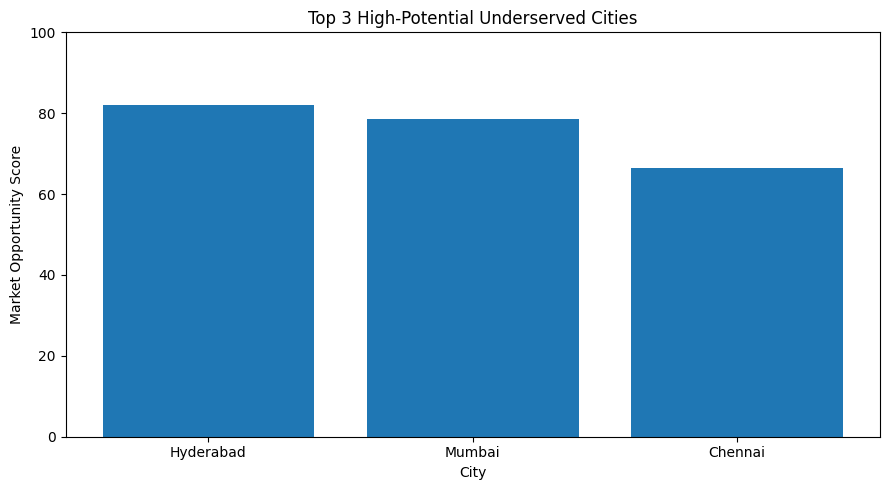

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(top_regions['City'], top_regions['Opportunity_Score'])
plt.title('Top 3 High-Potential Underserved Cities')
plt.xlabel('City')
plt.ylabel('Market Opportunity Score')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


In [12]:

!pip -q install folium

import folium

# Create India map
india_map = folium.Map(
    location=[22.5, 80.0],
    zoom_start=5,
    tiles='CartoDB positron'
)

# Add city markers
for _, row in city_analysis.iterrows():
    is_top = row['City'] in top_regions['City'].values

    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=10 if is_top else 6,
        popup=f"""
        City: {row['City']}<br>
        State: {row['State']}<br>
        Opportunity Score: {row['Opportunity_Score']:.2f}<br>
        Monthly Search Demand: {row['Avg_Search_Demand']:.0f}<br>
        Competitors: {row['Avg_Competitors']:.1f}
        """,
        tooltip=row['City'],
        color='red' if is_top else 'blue',
        fill=True,
        fill_opacity=0.7
    ).add_to(india_map)

# Save interactive map
india_map.save('India_Geospatial_Analysis.html')

india_map


/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [13]:

# Export regional analysis
city_analysis.to_csv('Regional_Market_Analysis.csv', index=False)

# Export top 3 regions
top_regions.to_csv('Top_3_Underserved_Regions.csv', index=False)

print("All analysis files saved successfully!")
print("1. India_Geospatial_Analysis.html")
print("2. Regional_Market_Analysis.csv")
print("3. Top_3_Underserved_Regions.csv")


All analysis files saved successfully!
1. India_Geospatial_Analysis.html
2. Regional_Market_Analysis.csv
3. Top_3_Underserved_Regions.csv


In [14]:

!pip -q install reportlab

import matplotlib.pyplot as plt
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, Image, PageBreak
)
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import inch

# Create opportunity chart
plt.figure(figsize=(8, 4))
plt.bar(top_regions['City'], top_regions['Opportunity_Score'])
plt.title('Top 3 Market Opportunity Regions')
plt.xlabel('City')
plt.ylabel('Opportunity Score')
plt.tight_layout()
plt.savefig('opportunity_chart.png', dpi=150)
plt.close()

# Create PDF
pdf = SimpleDocTemplate(
    'Geospatial_Data_Analysis_Report.pdf',
    pagesize=A4
)

styles = getSampleStyleSheet()
story = []

story.append(Paragraph(
    "GEOSPATIAL DATA ANALYSIS REPORT",
    styles['Title']
))
story.append(Spacer(1, 15))

story.append(Paragraph("1. Project Objective", styles['Heading2']))
story.append(Paragraph(
    "The objective of this project is to analyze regional market "
    "indicators across Indian cities, visualize geographical patterns, "
    "and identify three promising underserved markets for potential expansion.",
    styles['BodyText']
))
story.append(Spacer(1, 12))

story.append(Paragraph("2. Dataset Overview", styles['Heading2']))
story.append(Paragraph(
    f"The dataset contains {len(df)} records and {len(df.columns)} columns "
    f"after cleaning, covering {df['City'].nunique()} cities and "
    f"{df['State'].nunique()} states. It includes geographical coordinates, "
    "search demand, competition, income, conversion rate and acquisition cost.",
    styles['BodyText']
))
story.append(Spacer(1, 12))

story.append(Paragraph("3. Methodology", styles['Heading2']))
story.append(Paragraph(
    "The dataset was inspected and cleaned. Records were aggregated by city "
    "and state. A weighted opportunity score was calculated using demand (35%), "
    "low competition (25%), conversion rate (20%), income (10%) and low "
    "acquisition cost (10%). Higher scores indicate stronger relative market "
    "opportunity among the cities analyzed.",
    styles['BodyText']
))
story.append(Spacer(1, 12))

story.append(Paragraph("4. Top 3 Potential Regions", styles['Heading2']))

table_data = [
    ['City', 'State', 'Opportunity Score']
]

for _, row in top_regions.iterrows():
    table_data.append([
        str(row['City']),
        str(row['State']),
        f"{row['Opportunity_Score']:.2f}"
    ])

table = Table(table_data, colWidths=[150, 150, 150])
table.setStyle(TableStyle([
    ('BACKGROUND', (0, 0), (-1, 0), colors.darkblue),
    ('TEXTCOLOR', (0, 0), (-1, 0), colors.white),
    ('GRID', (0, 0), (-1, -1), 0.5, colors.grey),
    ('PADDING', (0, 0), (-1, -1), 8),
    ('ALIGN', (2, 0), (2, -1), 'CENTER')
]))
story.append(table)
story.append(Spacer(1, 15))

story.append(Paragraph("5. Market Opportunity Chart", styles['Heading2']))
story.append(Image('opportunity_chart.png', width=6*inch, height=3*inch))
story.append(Spacer(1, 12))

story.append(Paragraph("6. Key Findings", styles['Heading2']))

for _, row in top_regions.iterrows():
    story.append(Paragraph(
        f"{row['City']}, {row['State']}: Opportunity score "
        f"{row['Opportunity_Score']:.2f}.",
        styles['BodyText']
    ))
    story.append(Spacer(1, 5))

story.append(Spacer(1, 10))
story.append(Paragraph("7. Conclusion", styles['Heading2']))
story.append(Paragraph(
    "The analysis provides a comparative view of market opportunities "
    "across the cities represented in the dataset. The top three cities "
    "are recommended for further market research and expansion assessment. "
    "The opportunity scores are analytical indicators, not guaranteed "
    "sales or revenue forecasts.",
    styles['BodyText']
))
story.append(Spacer(1, 10))

story.append(Paragraph("8. Interactive Map", styles['Heading2']))
story.append(Paragraph(
    "The accompanying India_Geospatial_Analysis.html file contains "
    "the interactive geographical visualization of the analyzed cities.",
    styles['BodyText']
))

pdf.build(story)

print("PDF report generated successfully!")


PDF report generated successfully!
